# Modelo base (CNN) — Intel Image Classification

In [3]:
# Charbel Isaias Chavez Zavala A01711950

import os, random
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import classification_report, confusion_matrix

# Hiperparámetros y clases
SEED = 42
IMG_SIZE = (150, 150)
BATCH_SIZE = 32
EPOCHS = 20
CLASS_NAMES = ["buildings", "forest", "glacier", "mountain", "sea", "street"]
keras.utils.set_random_seed(SEED)

## Dataset

In [4]:
import kagglehub
DATA_DIR = kagglehub.dataset_download("puneet6060/intel-image-classification")

DATA_DIR = Path(DATA_DIR)
TRAIN_DIR = next(DATA_DIR.rglob("seg_train/seg_train"))
TEST_DIR = next(DATA_DIR.rglob("seg_test/seg_test"))
PRED_DIR = next(DATA_DIR.rglob("seg_pred/seg_pred"))

Using Colab cache for faster access to the 'intel-image-classification' dataset.


## Exploración de datos

           train  test
buildings   2191   437
forest      2271   474
glacier     2404   553
mountain    2512   525
sea         2274   510
street      2382   501 

Total: {'train': 14034, 'test': 3000} | sin etiqueta (pred): 7301


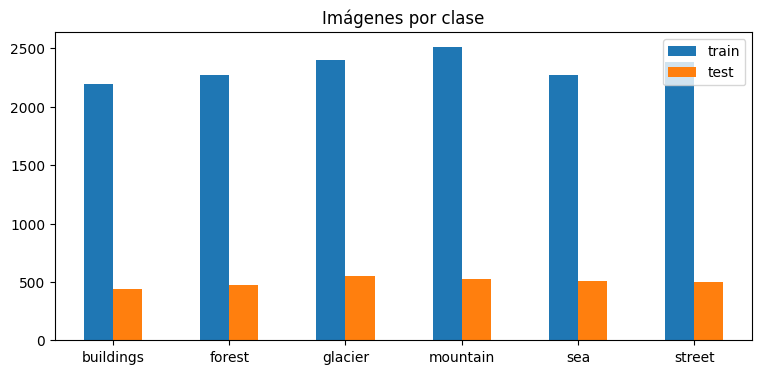

In [5]:
# Número de imágenes por clase en train y test
counts = pd.DataFrame({
    "train": {c: len(list((TRAIN_DIR / c).glob("*.jpg"))) for c in CLASS_NAMES},
    "test": {c: len(list((TEST_DIR / c).glob("*.jpg"))) for c in CLASS_NAMES},
})
print(counts, "\n\nTotal:", counts.sum().to_dict(), "| sin etiqueta (pred):", len(list(PRED_DIR.glob("*.jpg"))))

counts.plot.bar(figsize=(9, 4), rot=0, title="Imágenes por clase")
plt.show()

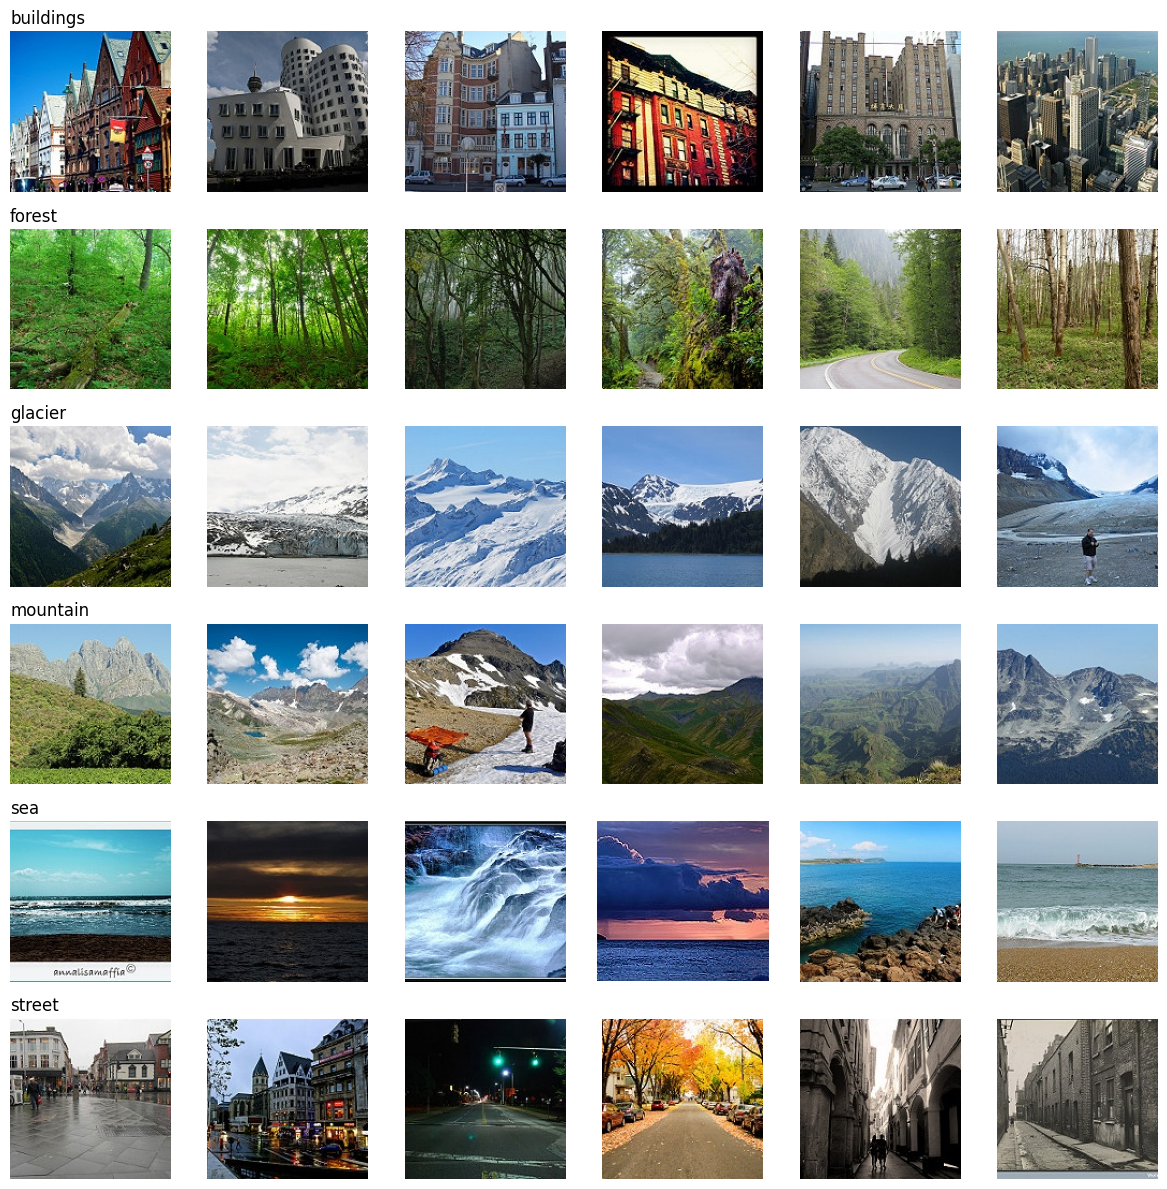

In [6]:
# Ejemplos aleatorios de cada clase
fig, axes = plt.subplots(len(CLASS_NAMES), 6, figsize=(12, 12))
for r, c in enumerate(CLASS_NAMES):
    for ax, f in zip(axes[r], random.Random(SEED).sample(list((TRAIN_DIR / c).glob("*.jpg")), 6)):
        ax.imshow(keras.utils.load_img(f)); ax.axis("off")
    axes[r, 0].set_title(c, loc="left")
plt.tight_layout(); plt.show()

## Preparación de datos

In [7]:
# Train/validation: 80/20 de seg_train con semilla fija. Test: seg_test
common = dict(class_names=CLASS_NAMES, image_size=IMG_SIZE, batch_size=BATCH_SIZE)
train_ds, val_ds = keras.utils.image_dataset_from_directory(
    TRAIN_DIR, validation_split=0.2, subset="both", seed=SEED, **common)
test_ds = keras.utils.image_dataset_from_directory(TEST_DIR, shuffle=False, **common)

# Cache en memoria + prefetch para acelerar el entrenamiento
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().prefetch(AUTOTUNE)
val_ds = val_ds.cache().prefetch(AUTOTUNE)
test_ds = test_ds.cache().prefetch(AUTOTUNE)

Found 14034 files belonging to 6 classes.
Using 11228 files for training.
Using 2806 files for validation.
Found 3000 files belonging to 6 classes.


## Modelo

In [8]:
# CNN base: 4 bloques Conv-ReLU-MaxPool + Dense. Sin regularización (referencia)
def build_baseline_cnn():
    inputs = keras.Input(shape=(*IMG_SIZE, 3))
    x = layers.Rescaling(1.0 / 255)(inputs)  # normaliza pixeles a [0, 1]
    for filters in (32, 64, 128, 128):
        x = layers.Conv2D(filters, 3, padding="same", activation="relu")(x)
        x = layers.MaxPooling2D()(x)
    x = layers.Flatten()(x)
    x = layers.Dense(128, activation="relu")(x)
    outputs = layers.Dense(len(CLASS_NAMES), activation="softmax")(x)
    return keras.Model(inputs, outputs, name="baseline_cnn")

model = build_baseline_cnn()
model.compile(optimizer=keras.optimizers.Adam(1e-3),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model.summary()

Model: "baseline_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 150, 150, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 75, 75, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 75, 75, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 37, 37, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 37, 37, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 18, 18, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 18, 18, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 9, 9, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 10368)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     1,327,232 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,568,838 (5.98 MB)

 Trainable params: 1,568,838 (5.98 MB)

 Non-trainable params: 0 (0.00 B)

## Entrenamiento

Epoch 1/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 69s 169ms/step - accuracy: 0.6457 - loss: 0.9112 - val_accuracy: 0.6842 - val_loss: 0.7769
Epoch 2/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 25s 29ms/step - accuracy: 0.7683 - loss: 0.6309 - val_accuracy: 0.7035 - val_loss: 0.7345
Epoch 3/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 10s 29ms/step - accuracy: 0.8080 - loss: 0.5216 - val_accuracy: 0.6949 - val_loss: 0.8387
Epoch 4/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 10s 29ms/step - accuracy: 0.8434 - loss: 0.4286 - val_accuracy: 0.7131 - val_loss: 0.9147
Epoch 5/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 10s 29ms/step - accuracy: 0.8710 - loss: 0.3582 - val_accuracy: 0.8272 - val_loss: 0.5427
Epoch 6/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 20s 29ms/step - accuracy: 0.8944 - loss: 0.2915 - val_accuracy: 0.8161 - val_loss: 0.6091
Epoch 7/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 10s 29ms/step - accuracy: 0.9183 - loss: 0.2276 - val_accuracy: 0.8111 - val_loss: 0.7340
Epoch 8/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 10s 30ms/step - accuracy: 0.9306 - loss: 0.1931 -

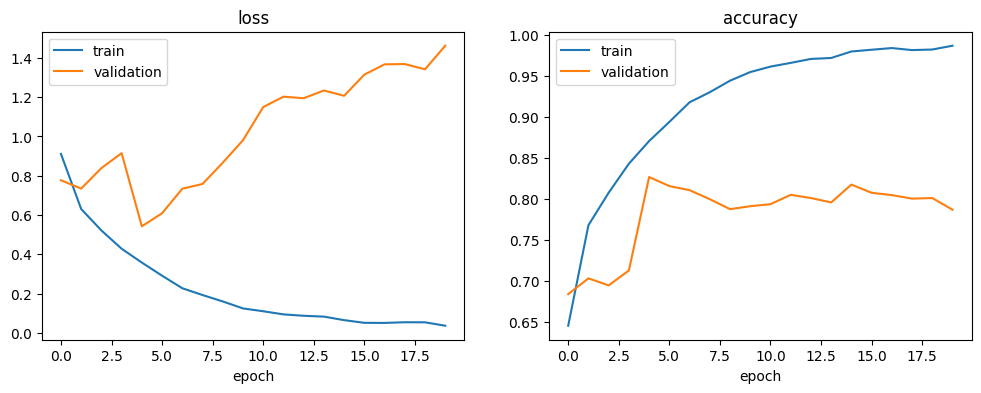

In [9]:
# Guarda el modelo de la época con mejor val_accuracy
checkpoint = keras.callbacks.ModelCheckpoint("baseline_cnn.keras", monitor="val_accuracy", save_best_only=True)
history = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS, callbacks=[checkpoint]).history

# Curvas de loss y accuracy
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, m in zip(axes, ["loss", "accuracy"]):
    ax.plot(history[m], label="train")
    ax.plot(history[f"val_{m}"], label="validation")
    ax.set_title(m); ax.set_xlabel("epoch"); ax.legend()
plt.show()

## Evaluación (validación y prueba)

=== validation ===
              precision    recall  f1-score   support

   buildings     0.8400    0.7814    0.8096       430
      forest     0.9032    0.9633    0.9323       436
     glacier     0.8492    0.7146    0.7761       473
    mountain     0.7661    0.8093    0.7871       514
         sea     0.7837    0.8658    0.8227       477
      street     0.8414    0.8361    0.8388       476

    accuracy                         0.8272      2806
   macro avg     0.8306    0.8284    0.8278      2806
weighted avg     0.8285    0.8272    0.8261      2806



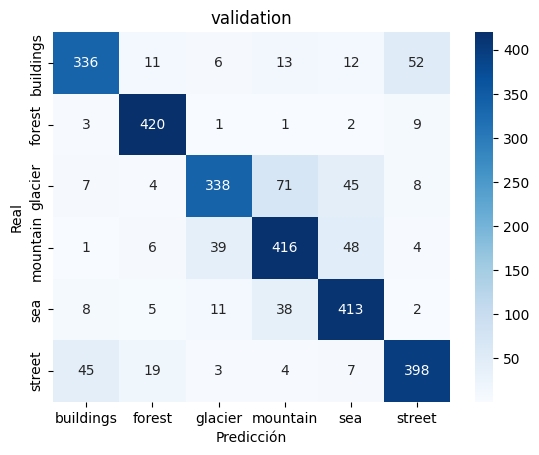

=== test ===
              precision    recall  f1-score   support

   buildings     0.8410    0.7986    0.8192       437
      forest     0.9168    0.9536    0.9349       474
     glacier     0.8500    0.6763    0.7533       553
    mountain     0.7417    0.8095    0.7741       525
         sea     0.7704    0.8686    0.8166       510
      street     0.8512    0.8563    0.8537       501

    accuracy                         0.8240      3000
   macro avg     0.8285    0.8272    0.8253      3000
weighted avg     0.8270    0.8240    0.8228      3000



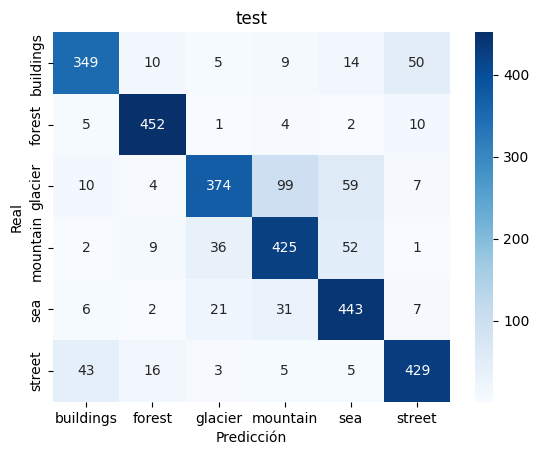

In [10]:
# Carga el mejor checkpoint y evalúa en validación y test
model = keras.models.load_model("baseline_cnn.keras")

for name, ds in [("validation", val_ds), ("test", test_ds)]:
    y_true = np.concatenate([y.numpy() for _, y in ds])
    y_pred = np.argmax(model.predict(ds, verbose=0), axis=1)
    print(f"=== {name} ===")
    print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=4))
    # Matriz de confusión
    cm = confusion_matrix(y_true, y_pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
    plt.xlabel("Predicción"); plt.ylabel("Real"); plt.title(name); plt.show()

## Predicciones (`seg_pred`)

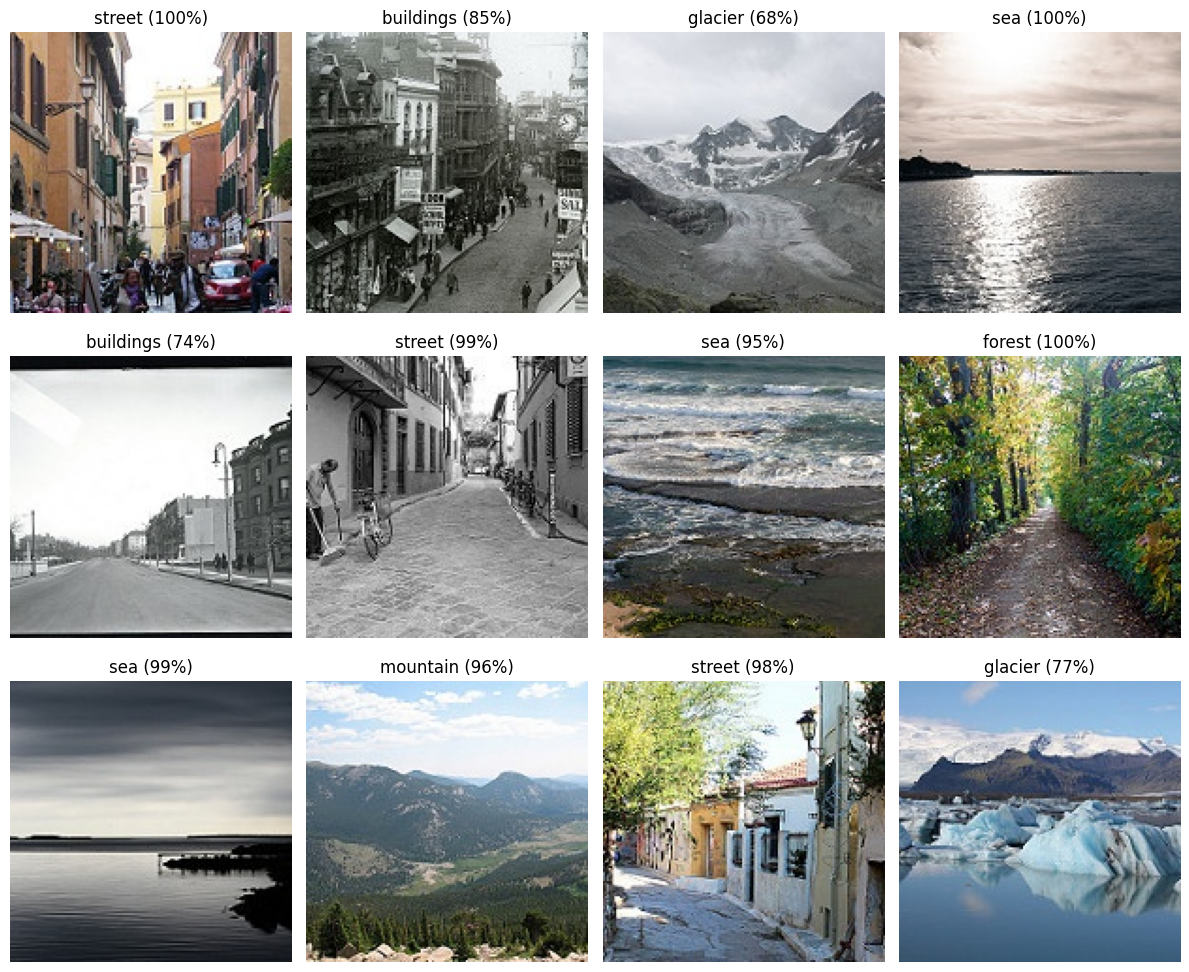

In [11]:
# Predice la clase de una imagen
def predict_image(path):
    img = keras.utils.load_img(path, target_size=IMG_SIZE)
    probs = model.predict(np.expand_dims(keras.utils.img_to_array(img), 0), verbose=0)[0]
    return img, probs

# 12 imágenes nuevas sin etiqueta
files = random.Random(SEED).sample(sorted(PRED_DIR.glob("*.jpg")), 12)
fig, axes = plt.subplots(3, 4, figsize=(12, 10))
for ax, f in zip(axes.ravel(), files):
    img, probs = predict_image(f)
    ax.imshow(img); ax.axis("off")
    ax.set_title(f"{CLASS_NAMES[probs.argmax()]} ({probs.max():.0%})")
plt.tight_layout(); plt.show()

## Predice tu propia imagen

Saving 97884118862aae9a192043cd0048e489.jpg to 97884118862aae9a192043cd0048e489 (1).jpg


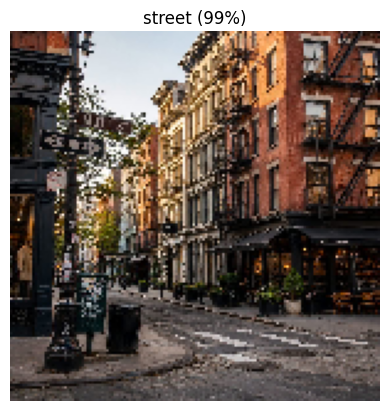

street: 0.99, buildings: 0.01, forest: 0.00


In [15]:
# Sube una o varias imágenes (jpg/png) y el modelo las clasifica
from google.colab import files as colab_files

for name in colab_files.upload():
    img, probs = predict_image(name)
    top3 = np.argsort(probs)[::-1][:3]
    plt.imshow(img); plt.axis("off")
    plt.title(f"{CLASS_NAMES[top3[0]]} ({probs[top3[0]]:.0%})"); plt.show()
    print(", ".join(f"{CLASS_NAMES[i]}: {probs[i]:.2f}" for i in top3))